In [1]:
#This is an example that uses the websockets api and the SaveImageWebsocket node to get images directly without
#them being saved to disk

import websocket #NOTE: websocket-client (https://github.com/websocket-client/websocket-client)
import uuid
import json
import urllib.request
import urllib.parse
import random
from PIL import Image
import io

from IPython.display import display
import matplotlib.pyplot as plt

server_address = "127.0.0.1:8188"
client_id = str(uuid.uuid4())

def queue_prompt(prompt):
    p = {"prompt": prompt, "client_id": client_id}
    data = json.dumps(p).encode('utf-8')
    req =  urllib.request.Request("http://{}/prompt".format(server_address), data=data)
    return json.loads(urllib.request.urlopen(req).read())

def get_image(filename, subfolder, folder_type):
    data = {"filename": filename, "subfolder": subfolder, "type": folder_type}
    url_values = urllib.parse.urlencode(data)
    with urllib.request.urlopen("http://{}/view?{}".format(server_address, url_values)) as response:
        return response.read()

def get_history(prompt_id):
    with urllib.request.urlopen("http://{}/history/{}".format(server_address, prompt_id)) as response:
        return json.loads(response.read())

def get_images(ws, prompt):
    prompt_id = queue_prompt(prompt)['prompt_id']
    output_images = {}
    current_node = ""
    while True:
        out = ws.recv()
        if isinstance(out, str):
            message = json.loads(out)
            if message['type'] == 'executing':
                data = message['data']
                if data['prompt_id'] == prompt_id:
                    if data['node'] is None:
                        break #Execution is done
                    else:
                        current_node = data['node']
        else:
            if current_node == 'save_image_websocket_node':
                images_output = output_images.get(current_node, [])
                images_output.append(out[8:])
                output_images[current_node] = images_output

    return output_images

In [2]:
prompt_text = """
{
  "5": {
    "inputs": {
      "width": 1024,
      "height": 1024,
      "batch_size": 4
    },
    "class_type": "EmptyLatentImage",
    "_meta": {
      "title": "Empty Latent Image"
    }
  },
  "6": {
    "inputs": {
      "text": "prompt",
      "clip": [
        "11",
        0
      ]
    },
    "class_type": "CLIPTextEncode",
    "_meta": {
      "title": "CLIP Text Encode (Prompt)"
    }
  },
  "8": {
    "inputs": {
      "samples": [
        "13",
        0
      ],
      "vae": [
        "10",
        0
      ]
    },
    "class_type": "VAEDecode",
    "_meta": {
      "title": "VAE Decode"
    }
  },
  "9": {
    "inputs": {
      "filename_prefix": "FLUX-Shnell2024-12-09 HH:12"
    },
    "class_type": "SaveImage",
    "_meta": {
      "title": "Save Image"
    }
  },
  "10": {
    "inputs": {
      "vae_name": "flux_ae.safetensors"
    },
    "class_type": "VAELoader",
    "_meta": {
      "title": "Load VAE"
    }
  },
  "11": {
    "inputs": {
      "clip_name1": "t5xxl_fp16.safetensors",
      "clip_name2": "clip_l.safetensors",
      "type": "flux"
    },
    "class_type": "DualCLIPLoader",
    "_meta": {
      "title": "DualCLIPLoader"
    }
  },
  "13": {
    "inputs": {
      "noise": [
        "25",
        0
      ],
      "guider": [
        "22",
        0
      ],
      "sampler": [
        "16",
        0
      ],
      "sigmas": [
        "17",
        0
      ],
      "latent_image": [
        "5",
        0
      ]
    },
    "class_type": "SamplerCustomAdvanced",
    "_meta": {
      "title": "SamplerCustomAdvanced"
    }
  },
  "16": {
    "inputs": {
      "sampler_name": "euler"
    },
    "class_type": "KSamplerSelect",
    "_meta": {
      "title": "KSamplerSelect"
    }
  },
  "17": {
    "inputs": {
      "scheduler": "simple",
      "steps": 18,
      "denoise": 1,
      "model": [
        "61",
        0
      ]
    },
    "class_type": "BasicScheduler",
    "_meta": {
      "title": "BasicScheduler"
    }
  },
  "22": {
    "inputs": {
      "model": [
        "61",
        0
      ],
      "conditioning": [
        "6",
        0
      ]
    },
    "class_type": "BasicGuider",
    "_meta": {
      "title": "BasicGuider"
    }
  },
  "25": {
    "inputs": {
      "noise_seed": 331164942376348
    },
    "class_type": "RandomNoise",
    "_meta": {
      "title": "RandomNoise"
    }
  },
  "61": {
    "inputs": {
      "unet_name": "flux1-dev-Q8_0.gguf"
    },
    "class_type": "UnetLoaderGGUF",
    "_meta": {
      "title": "Unet Loader (GGUF)"
    }
  },
  "save_image_websocket_node": {
    "inputs": {
      "images": [
        "8",
        0
      ]
    },
    "class_type": "SaveImageWebsocket",
    "_meta": {
      "title": "SaveImageWebsocket"
    }
  }
}

"""

# Rename last step from number to "save_image_websocket_node"
def gen_image(user_prompt):
    prompt = json.loads(prompt_text)
    #set the text prompt for our positive CLIPTextEncode
    prompt["6"]["inputs"]["text"] = "(animated movie, hiqh quality)" + user_prompt
    
    #set the seed for our KSampler node
    prompt["25"]["inputs"]["noise_seed"] = random.randint(0, 2_147_483_648)
    
    ws = websocket.WebSocket()
    ws.connect("ws://{}/ws?clientId={}".format(server_address, client_id))
    images = get_images(ws, prompt)
    ws.close() # for in case this example is used in an environment where it will be repeatedly called, like in a Gradio app. otherwise, you'll randomly receive connection timeouts
    #Commented out code to display the output images:
    result = []
    for node_id in images:
        for image_data in images[node_id]:
            image = Image.open(io.BytesIO(image_data))
            result.append(image)
    return result
            

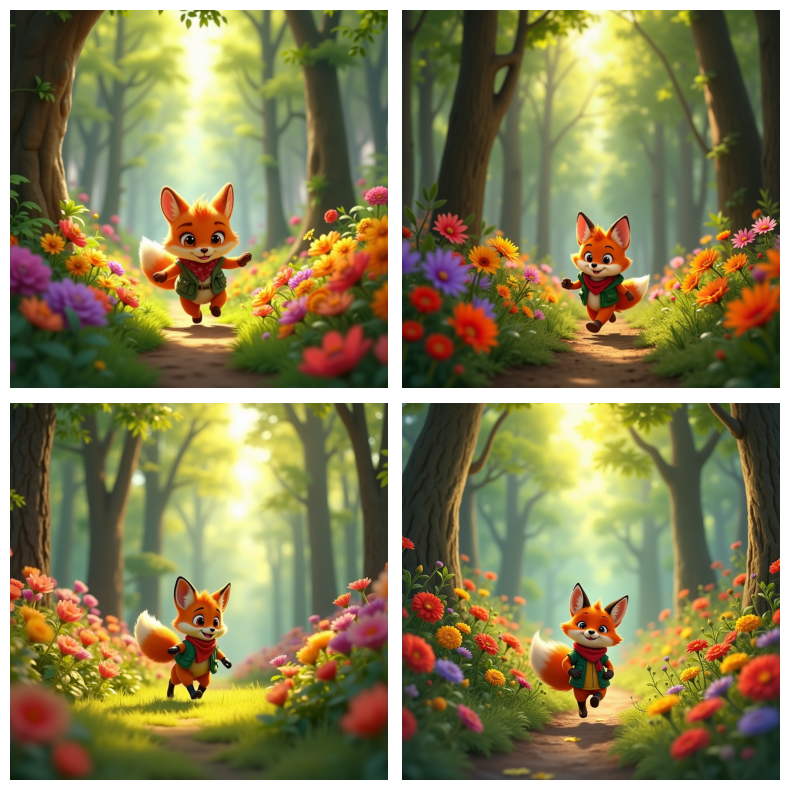

In [4]:
user_prompt = "A vibrant magical forest filled with tall, majestic trees and colorful flowers in various shades of red, yellow, and purple. A small, fluffy orange fox with a white-tipped tail, bright eyes, and a playful smile is darting between the bushes, wearing a tiny green explorer's vest and a red bandana. Soft sunlight filters through the leaves, illuminating the scene and highlighting the cheerful colors, capturing the essence of a sunny day in spring."
images = gen_image(user_prompt)
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.flatten()
for idx, image in enumerate(images):
    axes[idx].imshow(image)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()